# Assignment 2

## Extract data from the json file

Write a script, that would extract all the the data from the json file and return it in a list of texts for further use in the next tasks

In [1]:
import json


def extract_texts_from_file(file_path):
    """
    Extract text data from the JSON file.

    Args:
        file_path (str): Relative location of the JSON file in the project.

    Returns:
        list: The list of texts as strings.
    """
    with open(file_path, "r", encoding="utf-8") as file:
        data = json.load(file)

    if isinstance(data, dict) and "daily" in data:
        texts = [
            entry["weather_description"]
            for entry in data["daily"]
            if isinstance(entry, dict) and isinstance(entry.get("weather_description"), str)
        ]
    elif isinstance(data, list):
        texts = [
            item["text"]
            for item in data
            if isinstance(item, dict) and isinstance(item.get("text"), str)
        ]
    else:
        raise ValueError("Expected a JSON list of text records or a weather JSON object with a daily list.")

    if not texts:
        raise ValueError("No text entries were found in the JSON file.")

    return texts


texts = extract_texts_from_file("resources/weather.json")
print(texts)

['Clear sky', 'Light rain', 'Moderate rain', 'Sunny']


## Process the texts

Write a script, that would process these texts. Processing should include:

- Lowercasing
- Removing Punctuation
- Removing Special Characters and Numbers
- Stemming or Lemmatization
- Handling Abbreviations
- Spelling Correction

In [2]:
import re


def process_texts(texts):
    """
    Process the texts

    Args:
        texts (list): list of str texts to be processed.

    Returns:
        list: The list of texts as strings processed by script.
    """
    abbreviations = {
        "dr.": "doctor",
        "mr.": "mister",
        "mrs.": "missus",
        "etc.": "et cetera",
        "vs.": "versus",
    }
    spelling_corrections = {
        "teh": "the",
        "recieve": "receive",
        "seperate": "separate",
        "occurrance": "occurrence",
    }
    processed_texts = []

    for text in texts:
        text = text.lower()

        for abbr, full in abbreviations.items():
            text = text.replace(abbr, full)

        text = re.sub(r"[^a-z\s]", " ", text)
        words = [spelling_corrections.get(word, word) for word in text.split()]

        stemmed_words = []
        for word in words:
            if len(word) > 5 and word.endswith("ies"):
                word = word[:-3] + "y"
            elif len(word) > 5 and word.endswith("ing"):
                word = word[:-3]
            elif len(word) > 4 and word.endswith("ed"):
                word = word[:-2]
            elif len(word) > 4 and word.endswith("s") and not word.endswith("ss"):
                word = word[:-1]
            stemmed_words.append(word)

        processed_texts.append(" ".join(stemmed_words))

    return processed_texts

texts_processed = process_texts(texts)
print(texts_processed)

['clear sky', 'light rain', 'moderate rain', 'sunny']


## Calculate cosine similarities using TFIDF

Calculate the TFIDF score and cosine similarity between the texts. You may use gensim, write your own script using numpy or use other module. Output the result as a matrix $n\times n$  of cosine similarity scores (where $n$ is the length of texts list).

Extra credit: use word2vec word embeddings in vector spaces to get better TFIDF scores by representing each word as a vector.

In [3]:
def calculate_tfidf(texts_processed):
    """
    Calculate TFIDF score between the texts in the list.

    Args:
        texts_processed (list): list of texts, processed in previous task.

    Returns:
        cosine_matrix (list): a matrix of cosine similarity scores.
    """
    from sklearn.feature_extraction.text import TfidfVectorizer
    from sklearn.metrics.pairwise import cosine_similarity

    vectorized = TfidfVectorizer()
    tfidf_matrix = vectorized.fit_transform(texts_processed)
    cosine_matrix = cosine_similarity(tfidf_matrix, tfidf_matrix)
    return cosine_matrix

texts = extract_texts_from_file("resources/weather.json")
texts_processed = process_texts(texts)

cosine_matrix = calculate_tfidf(texts_processed)
print(cosine_matrix)

[[1.         0.         0.         0.        ]
 [0.         1.         0.38332232 0.        ]
 [0.         0.38332232 1.         0.        ]
 [0.         0.         0.         1.        ]]


## Visualize data

Visualize the cosine_matrix data using matplotlib. Choose your own method of plotting the scores in a way, that the similarity indeces between texts would be instantly visible. Plot data about texts as well (a couple of first words in the document).

*Hint: remember heat maps, aren't they nice for this task?*

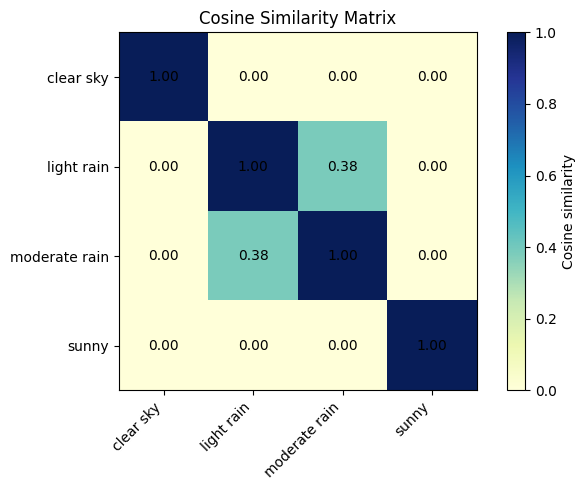

In [4]:
import numpy as np
import matplotlib.pyplot as plt

def visualize_data(cosine_matrix, texts_processed):
    """
    Visualize the cosine similarity matrix from the previous task. 

    Args:
        cosine_matrix (list): matrix of cosine similarity scores (values from 0.0 to 1.0 expected).
        texts_processed (list): list of texts, processed in previous task.

    Returns:
        None: None.
    """
    matrix = np.asarray(cosine_matrix)
    labels = [text[:30] + "..." if len(text) > 30 else text for text in texts_processed]

    fig, ax = plt.subplots(figsize=(max(7, len(labels) * 1.2), max(5, len(labels) * 0.8)))
    image = ax.imshow(matrix, cmap="YlGnBu", vmin=0, vmax=1)
    ax.set_xticks(range(len(labels)), labels=labels, rotation=45, ha="right")
    ax.set_yticks(range(len(labels)), labels=labels)
    ax.set_title("Cosine Similarity Matrix")
    fig.colorbar(image, ax=ax, label="Cosine similarity")

    for row in range(matrix.shape[0]):
        for column in range(matrix.shape[1]):
            ax.text(column, row, f"{matrix[row, column]:.2f}", ha="center", va="center")

    fig.tight_layout()
    plt.show()

visualize_data(cosine_matrix, texts_processed)

## Analyse your own text using TFIDF (or any other method)

Analyse your own text using previous methods. You may use API fetching to get text data, download texts from Kaggle or use any texts you want. Find cosine similarities and visualize them

Recommendation: use sentence_transform / openai embedding model

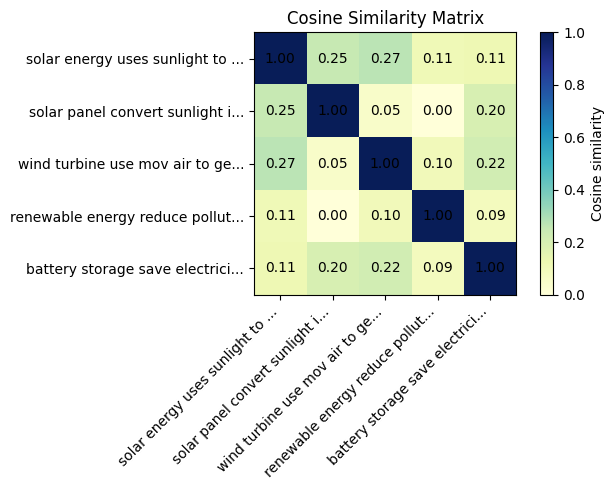

In [5]:
import requests

def get_texts():
    """
    Get the texts you want to analyse. Either API fetching, Kaggle or any other source.

    Args:
        None: None.

    Returns:
        list: list of texts.
    """
    return [
        "Solar energy uses sunlight to generate clean electricity.",
        "Solar panels convert sunlight into electricity for homes.",
        "Wind turbines use moving air to generate renewable electricity.",
        "Renewable energy reduces pollution and protects the environment.",
        "Battery storage saves electricity produced by solar panels and wind turbines.",
    ]

texts = get_texts()
texts_processed = process_texts(texts)
cosine_matrix = calculate_tfidf(texts_processed)
visualize_data(cosine_matrix, texts_processed)